# Reto avanzado 3 · Estabilidad de los clusters: Jackknife Clustering

**Clustering the Star — Mercedes-Benz · III Malackathon 2026**

Un modelo puede tener un silhouette aceptable y, aun así, producir segmentos **inestables**: si quitamos unos pocos
clientes y re-entrenamos, los grupos cambian. Antes de basar decisiones de marketing en los 6 segmentos, comprobamos que
**no dependen de qué clientes concretos estén en los datos**.

**Jackknife Clustering:** se generan N submuestras excluyendo cada vez un % aleatorio de clientes, se re-entrena el
modelo en cada una y se comparan las asignaciones de los clientes que aparecen en varias submuestras.

| Pregunta | Apartado |
|---|---|
| ¿Se mantienen los segmentos al quitar un 10-20 % de clientes? | 2-3 |
| ¿Qué % de clientes cae siempre en el mismo segmento? | 4 |
| ¿Hay algún segmento especialmente inestable? ¿Quién "salta"? | 5-6 |
| ¿Es esta estabilidad mérito de los datos o la tendría cualquier dato? | 7 |
| ¿Hay alguna fragilidad escondida? | 8 |
| ¿Era k = 6 una elección estable? | 9 |

In [1]:
import itertools
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_samples

from features import (cargar_datos, construir_pipeline, ajustar_kmeans, nombrar_segmentos, ORDEN_SEGMENTOS,
                      COLORES_SEGMENTOS, K_FINAL, N_INIT_FINAL, SEMILLA)

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.3f}".format)

df = cargar_datos()
pipe = construir_pipeline()
X = pipe.fit_transform(df)
clientes = pipe.named_steps["agregar"].transform(df)
km = ajustar_kmeans(X)
ref = pd.Series(km.labels_, index=X.index, name="referencia")
NOMBRES = nombrar_segmentos(pd.DataFrame(km.cluster_centers_, columns=X.columns))
seg_ref = ref.map(NOMBRES)
ids = X.index.to_numpy()
print(f"Modelo de referencia: {len(X):,} clientes, k = {K_FINAL}, n_init = {N_INIT_FINAL}")

Modelo de referencia: 173,456 clientes, k = 6, n_init = 50


## 1. Diseño del experimento (y trampas que evitamos)

| Decisión | Por qué |
|---|---|
| **Se excluyen clientes, no filas** | El CSV tiene una fila por relación cliente–vehículo. Quitar filas sueltas cambiaría los agregados de los clientes que se quedan (nº de vehículos, % electrificado…): estaríamos comparando clientes distintos. Se quita al cliente con **todas** sus filas |
| **Se re-entrena el pipeline completo** en cada submuestra | Los percentiles por país, el escalado y las medianas de imputación dependen de qué clientes haya. Son parte del modelo, así que también se re-calculan |
| **20 submuestras con 20 % excluido** (y otras 20 con 10 %) | El rango que pide el reto; con 20 %, cada cliente aparece de media en 16 de las 20 ejecuciones |
| **Mismo modelo final**: k = 6, `n_init = 50` | Es el modelo que se usa para marketing (Reto 3) |
| **Alinear etiquetas** antes de comparar | El "cluster 2" de una ejecución no tiene por qué ser el "cluster 2" de otra. Se emparejan con el **algoritmo húngaro** contra el modelo de referencia (el que maximiza los clientes coincidentes) |
| **Métricas sin etiquetas** además de la coincidencia | El ARI y la Jaccard por cluster no dependen del emparejamiento, así que no puede "maquillarlo" |
| **Un control** | Mismo dato completo, solo cambiando la semilla: separa la inestabilidad debida a los datos de la debida a la inicialización |

In [2]:
def entrenar_submuestra(frac_excluida, semilla, refit=True, n_init=N_INIT_FINAL, k=K_FINAL):
    """Excluye un % aleatorio de CLIENTES, re-entrena (pipeline + K-Means) y devuelve etiquetas e inercia."""
    rng = np.random.default_rng(semilla)
    dentro = rng.choice(ids, int(round(len(ids) * (1 - frac_excluida))), replace=False)
    if refit:
        Xs = construir_pipeline().fit_transform(df[df["client_id"].isin(dentro)])
    else:
        Xs = X.loc[dentro]
    m = KMeans(n_clusters=k, n_init=n_init, random_state=semilla).fit(Xs)
    return pd.Series(m.labels_, index=Xs.index), m.inertia_


def alinear(etiquetas, referencia=ref, k=K_FINAL):
    """Renombra los clusters de una ejecución para que coincidan al máximo con la referencia (algoritmo húngaro)."""
    cm = pd.crosstab(etiquetas, referencia.loc[etiquetas.index]).reindex(index=range(k), columns=range(k), fill_value=0)
    filas, cols = linear_sum_assignment(-cm.values)
    return etiquetas.map(dict(zip(cm.index[filas], cm.columns[cols])))


N_SUB = 20
inicio = time.time()
jk20 = [entrenar_submuestra(0.20, 1000 + i) for i in range(N_SUB)]
jk10 = [entrenar_submuestra(0.10, 1100 + i) for i in range(N_SUB)]
control = [pd.Series(KMeans(K_FINAL, n_init=N_INIT_FINAL, random_state=2000 + i).fit(X).labels_, index=X.index) for i in range(10)]
print(f"{2 * N_SUB} submuestras re-entrenadas + 10 controles en {time.time() - inicio:,.0f} s")

40 submuestras re-entrenadas + 10 controles en 327 s


## 2. ¿Se mantienen los segmentos?

Tres medidas para cada ejecución:
- **ARI con la referencia** (1 = mismas asignaciones, salvo el nombre del cluster; 0 = como al azar).
- **% de coincidencia**: clientes que caen en el mismo segmento que en la referencia, tras alinear etiquetas.
- **ARI y coincidencia entre pares de ejecuciones**, sobre los clientes que comparten (190 pares por escenario).

In [3]:
def resumen_escenario(runs):
    labs = [l for l, _ in runs]
    alineadas = [alinear(l) for l in labs]
    pares = list(itertools.combinations(range(len(labs)), 2))
    def comun(a, b):
        return a.index.intersection(b.index)
    return {
        "ARI con la referencia": [adjusted_rand_score(ref.loc[l.index], l) for l in labs],
        "% coincidencia con la referencia": [(a == ref.loc[a.index]).mean() * 100 for a in alineadas],
        "ARI entre ejecuciones": [adjusted_rand_score(labs[i].loc[comun(labs[i], labs[j])], labs[j].loc[comun(labs[i], labs[j])]) for i, j in pares],
        "% coincidencia entre ejecuciones": [(alineadas[i].loc[comun(labs[i], labs[j])] == alineadas[j].loc[comun(labs[i], labs[j])]).mean() * 100 for i, j in pares],
    }, alineadas

res20, al20 = resumen_escenario(jk20)
res10, al10 = resumen_escenario(jk10)
res_ctrl = {"ARI con la referencia": [adjusted_rand_score(ref, c) for c in control],
            "% coincidencia con la referencia": [(alinear(c) == ref).mean() * 100 for c in control]}
tabla = pd.DataFrame({
    f"{esc} · {met}": {"media": np.mean(v), "mínimo": np.min(v), "máximo": np.max(v)}
    for esc, r in [("20 % excluido", res20), ("10 % excluido", res10), ("control (solo semilla)", res_ctrl)] for met, v in r.items()}).T
tabla

,media,mínimo,máximo
20 % excluido · ARI con la referencia,0.995,0.991,0.997
20 % excluido · % coincidencia con la referencia,99.803,99.668,99.881
20 % excluido · ARI entre ejecuciones,0.993,0.982,0.997
20 % excluido · % coincidencia entre ejecuciones,99.728,99.395,99.897
10 % excluido · ARI con la referencia,0.996,0.992,0.998
10 % excluido · % coincidencia con la referencia,99.836,99.710,99.930
10 % excluido · ARI entre ejecuciones,0.994,0.985,0.998
10 % excluido · % coincidencia entre ejecuciones,99.777,99.477,99.904
control (solo semilla) · ARI con la referencia,0.997,0.994,0.999
control (solo semilla) · % coincidencia con la referencia,99.901,99.809,99.978


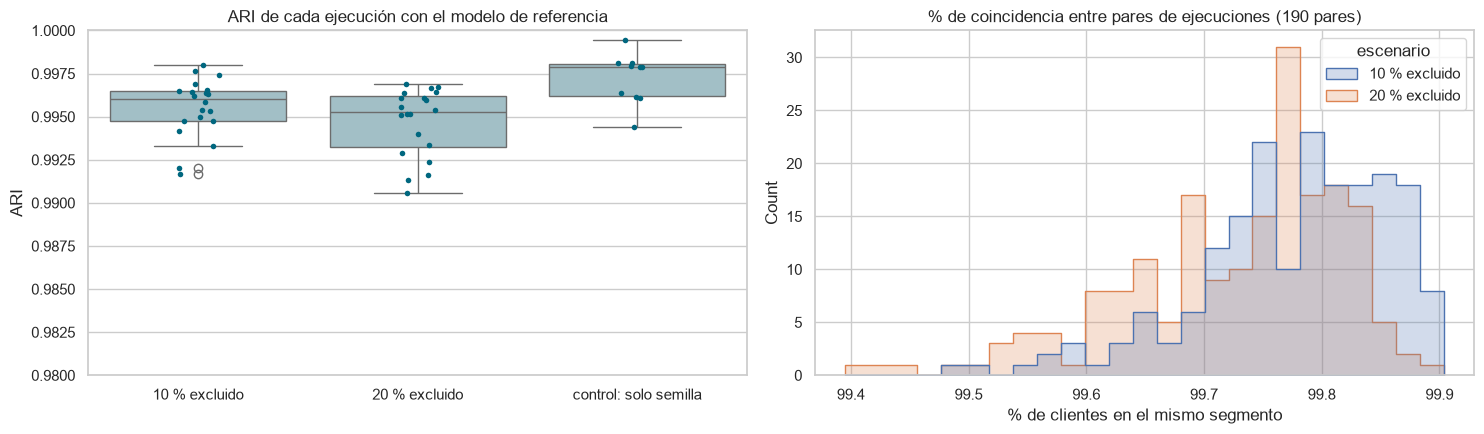

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
datos = pd.DataFrame([(esc, v) for esc, r in [("10 % excluido", res10), ("20 % excluido", res20), ("control: solo semilla", res_ctrl)]
                      for v in r["ARI con la referencia"]], columns=["escenario", "ARI"])
sns.boxplot(data=datos, x="escenario", y="ARI", ax=axes[0], color="#9cc3cc")
sns.stripplot(data=datos, x="escenario", y="ARI", ax=axes[0], color="#00677F", size=4)
axes[0].set(title="ARI de cada ejecución con el modelo de referencia", ylim=(0.98, 1.0), xlabel="")
datos = pd.DataFrame([(esc, v) for esc, r in [("10 % excluido", res10), ("20 % excluido", res20)]
                      for v in r["% coincidencia entre ejecuciones"]], columns=["escenario", "coincidencia"])
sns.histplot(data=datos, x="coincidencia", hue="escenario", bins=25, ax=axes[1], element="step")
axes[1].set(title="% de coincidencia entre pares de ejecuciones (190 pares)", xlabel="% de clientes en el mismo segmento")
plt.tight_layout()
plt.show()

**Lectura:**
- Quitando un **20 %** de los clientes y re-entrenando todo, cada ejecución reproduce la segmentación de referencia con
  un **ARI de 0,99** y un **99,7-99,9 % de clientes en el mismo segmento**. Entre dos ejecuciones cualesquiera (que
  comparten ~64 % de clientes), coinciden más del 99,4 %.
- Con un **10 %** excluido el resultado es todavía un poco más estable, como cabe esperar.
- El **control** (mismos datos, otra semilla) da casi lo mismo que el jackknife: casi toda la pequeña variación que
  queda viene de la **inicialización** de K-Means, no de qué clientes haya en los datos.

## 3. ¿Pesa el re-cálculo del preprocesado?

Las ejecuciones anteriores re-calculan percentiles y escalado en cada submuestra. ¿Cambia algo si se usa la matriz ya
preparada con todos los clientes y solo se re-entrena K-Means?

In [5]:
fijo = [entrenar_submuestra(0.20, 1000 + i, refit=False) for i in range(10)]
pd.DataFrame({
    "pipeline re-entrenado": [adjusted_rand_score(ref.loc[l.index], l) for l, _ in jk20[:10]],
    "preprocesado fijo": [adjusted_rand_score(ref.loc[l.index], l) for l, _ in fijo],
}).agg(["mean", "min"]).rename(index={"mean": "ARI medio", "min": "ARI mínimo"})

,pipeline re-entrenado,preprocesado fijo
ARI medio,0.995,0.995
ARI mínimo,0.992,0.991


Prácticamente igual (con las mismas 10 submuestras). Los percentiles por país y el escalado son **robustos** a quitar
un 20 % de clientes: las features del Reto 2 no introducen inestabilidad.

## 4. Estabilidad de cada cliente

Con las etiquetas ya alineadas, para cada cliente se cuenta en cuántas ejecuciones aparece y qué parte de ellas cae en
su segmento más frecuente. **Estabilidad = 1** significa que cae siempre en el mismo segmento.

In [6]:
M = pd.concat(al20, axis=1).reindex(ref.index)
veces = M.notna().sum(axis=1)
moda = M.mode(axis=1)[0]
estabilidad = M.eq(moda, axis=0).sum(axis=1) / veces
clientes["estabilidad"] = estabilidad
clientes["salta"] = estabilidad < 1
pd.Series({
    "veces que aparece cada cliente (media)": veces.mean(),
    "  mínimo / máximo": f"{veces.min()} / {veces.max()}",
    "% clientes con estabilidad 100 %": (estabilidad == 1).mean() * 100,
    "clientes que saltan alguna vez": int(clientes["salta"].sum()),
    "% clientes con estabilidad < 80 %": (estabilidad < .8).mean() * 100,
    "% clientes cuyo segmento más frecuente = el de referencia": (moda == ref).mean() * 100,
}).to_frame("valor")

,valor
veces que aparece cada cliente (media),16.000
mínimo / máximo,7 / 20
% clientes con estabilidad 100 %,99.104
clientes que saltan alguna vez,1555
% clientes con estabilidad < 80 %,0.362
% clientes cuyo segmento más frecuente = el de referencia,99.923


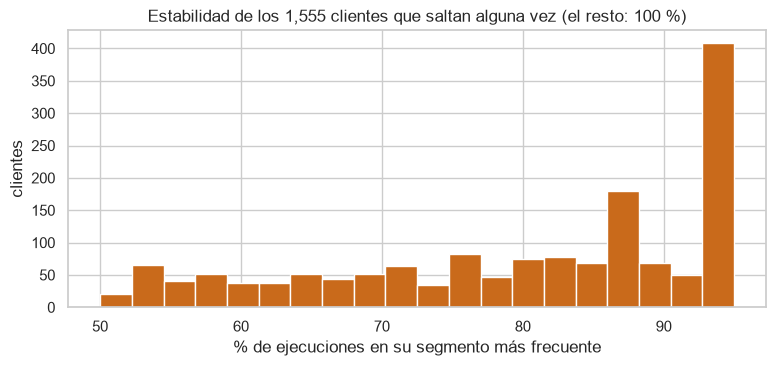

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.6))
estabilidad[estabilidad < 1].mul(100).plot.hist(bins=20, ax=ax, color="#c96a1b")
ax.set(title=f"Estabilidad de los {int(clientes['salta'].sum()):,} clientes que saltan alguna vez (el resto: 100 %)",
       xlabel="% de ejecuciones en su segmento más frecuente", ylabel="clientes")
plt.show()

El **99,1 %** de los clientes cae **siempre** en el mismo segmento. Solo ~1.550 clientes (0,9 %) cambian alguna vez, y la
mayoría lo hace solo en una o dos de sus ejecuciones.

## 5. ¿Hay algún segmento especialmente inestable?

Dos medidas por segmento:
- **% de clientes que saltan** alguna vez.
- **Jaccard de Hennig** (medida estándar de estabilidad por cluster, sin depender del emparejamiento): para cada
  segmento de referencia, el máximo solapamiento (intersección / unión) con algún cluster de cada ejecución. Escala
  habitual: **> 0,85 muy estable**, 0,75-0,85 estable, 0,6-0,75 patrón débil, < 0,5 el cluster "se disuelve".

In [8]:
def jaccard_por_cluster(etiquetas):
    r = ref.loc[etiquetas.index]
    out = {}
    for c in range(K_FINAL):
        A = r.index[r == c]
        out[NOMBRES[c]] = max(len(A.intersection(etiquetas.index[etiquetas == d])) / len(A.union(etiquetas.index[etiquetas == d]))
                              for d in np.unique(etiquetas))
    return out

jac = pd.DataFrame([jaccard_por_cluster(l) for l, _ in jk20])
por_seg = pd.DataFrame({
    "Jaccard media": jac.mean(), "Jaccard mínima": jac.min(),
    "% clientes que saltan": clientes.groupby(seg_ref)["salta"].mean() * 100,
    "clientes que saltan": clientes.groupby(seg_ref)["salta"].sum(),
    "estabilidad media (%)": clientes.groupby(seg_ref)["estabilidad"].mean() * 100,
}).reindex(ORDEN_SEGMENTOS)
por_seg

,Jaccard media,Jaccard mínima,% clientes que saltan,clientes que saltan,estabilidad media (%)
Premium Multivehículo,0.994,0.986,1.453,324,99.675
Fiel de Taller,0.994,0.990,1.340,609,99.745
Pionero Eléctrico,0.999,0.996,0.299,74,99.949
Gran Formato,0.999,0.998,0.165,25,99.959
Recién Llegado de Ocasión,0.996,0.992,0.863,405,99.824
Contacto Solo Digital,0.997,0.996,0.626,118,99.874


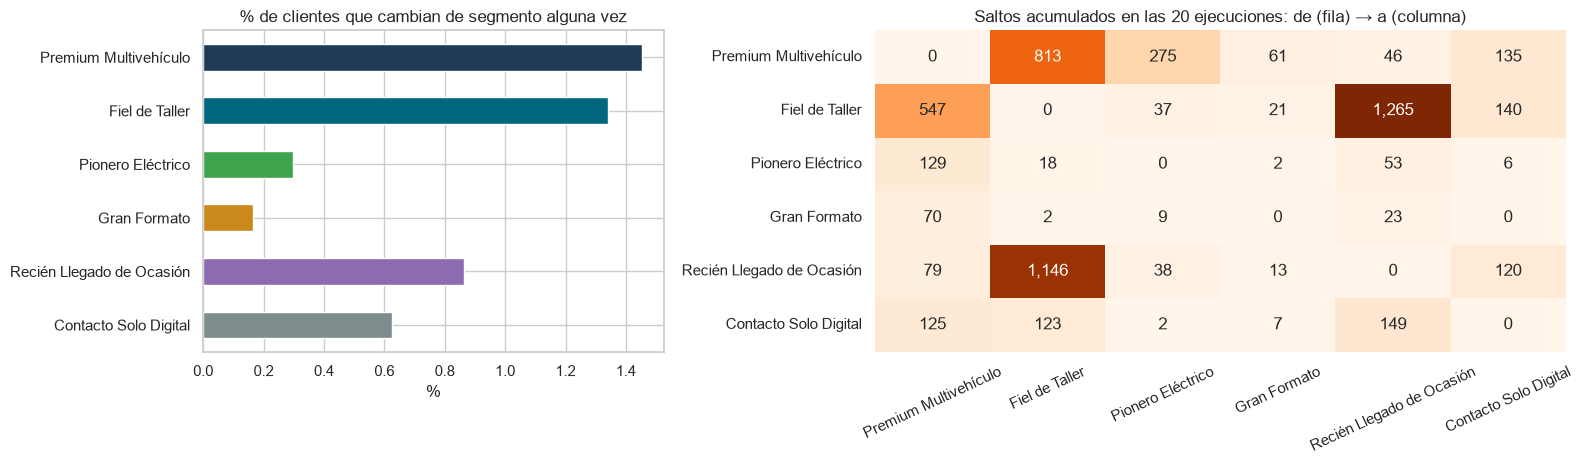

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [2, 3]})
por_seg["% clientes que saltan"].plot.barh(ax=axes[0], color=[COLORES_SEGMENTOS[s] for s in ORDEN_SEGMENTOS])
axes[0].invert_yaxis()
axes[0].set(title="% de clientes que cambian de segmento alguna vez", xlabel="%", ylabel="")
# Transiciones: segmento de referencia → segmento al que salta (sumando todas las ejecuciones)
saltos = []
for a in al20:
    r = ref.loc[a.index]
    cambia = a != r
    saltos.append(pd.crosstab(r[cambia].map(NOMBRES), a[cambia].map(NOMBRES)))
trans = sum(s.reindex(index=ORDEN_SEGMENTOS, columns=ORDEN_SEGMENTOS, fill_value=0) for s in saltos)
sns.heatmap(trans, annot=True, fmt=",.0f", cmap="Oranges", ax=axes[1], cbar=False)
axes[1].set(title="Saltos acumulados en las 20 ejecuciones: de (fila) → a (columna)", xlabel="", ylabel="")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

**Lectura por segmento:**
- **Todos los segmentos son muy estables** (Jaccard media ≥ 0,99 y mínima 0,986, muy por encima del umbral de 0,85).
- **Gran Formato y Pionero Eléctrico** son los más sólidos (≤ 0,3 % de clientes que saltan): los define un rasgo
  casi binario (furgoneta, electrificado) y no hay clientes "a medias".
- **Premium Multivehículo y Fiel de Taller** son los menos estables (~1,3-1,5 % saltan). Los saltos tienen dirección:
  - **Fiel de Taller ↔ Recién Llegado de Ocasión**: el par con más intercambios. Los separa el uso del taller, una
    variable continua: los clientes con un uso intermedio quedan en la frontera.
  - **Premium Multivehículo ↔ Fiel de Taller**: clientes con 2 coches o un leasing, pero sin el resto del perfil
    premium. Es el segmento más heterogéneo (Reto 3: silhouette 0,05; Reto 4: tres sub-perfiles).

## 6. ¿Quién salta? Los clientes de la frontera

Para cada cliente se mide su **margen**: cuánto más cerca está de su centroide que del segundo más cercano (0 = justo
en la frontera entre dos segmentos; cerca de 1 = en el centro de su segmento) y cuál es su **segundo segmento más
cercano**.

In [10]:
dist = np.sqrt(((X.values[:, None, :] - km.cluster_centers_[None]) ** 2).sum(-1))
orden = np.sort(dist, axis=1)
clientes["margen"] = (orden[:, 1] - orden[:, 0]) / orden[:, 1]
clientes["segundo_segmento"] = pd.Series(np.argsort(dist, axis=1)[:, 1], index=X.index).map(NOMBRES)
decil = pd.qcut(clientes["margen"], 10, labels=[f"D{i}" for i in range(1, 11)])
por_decil = clientes.groupby(decil, observed=True).agg(margen_max=("margen", "max"), pct_saltan=("salta", "mean"))
por_decil["pct_saltan"] *= 100
display(por_decil.T)
print(f"El {clientes.loc[clientes['salta'], 'margen'].le(por_decil['margen_max'].iloc[0]).mean():.0%} de los que saltan está en el 10 % de clientes más cercano a una frontera")
pd.crosstab(seg_ref[clientes["salta"]], clientes.loc[clientes["salta"], "segundo_segmento"]).reindex(index=ORDEN_SEGMENTOS, columns=ORDEN_SEGMENTOS, fill_value=0)

margen,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10
margen_max,0.055,0.108,0.152,0.195,0.235,0.276,0.318,0.363,0.423,0.782
pct_saltan,8.965,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


El 100% de los que saltan está en el 10 % de clientes más cercano a una frontera


segundo_segmento,Premium Multivehículo,Fiel de Taller,Pionero Eléctrico,Gran Formato,Recién Llegado de Ocasión,Contacto Solo Digital
referencia,,,,,,
Premium Multivehículo,0,178,76,18,17,35
Fiel de Taller,201,0,14,4,355,35
Pionero Eléctrico,54,5,0,1,12,2
Gran Formato,18,1,1,0,5,0
Recién Llegado de Ocasión,26,334,10,3,0,32
Contacto Solo Digital,38,40,2,1,37,0


**Todos los clientes que saltan están en el 10 % con menor margen**: no hay saltos "sorpresa" en el centro de ningún
segmento. Y su segundo segmento más cercano coincide con los saltos del apartado 5 (Fiel de Taller ↔ Recién Llegado,
Premium ↔ Fiel de Taller): el salto no es aleatorio, es una frontera difusa entre dos perfiles concretos.

**¿Silhouette negativo = inestable? No.** En el Reto 3, el 40 % de los clientes de Premium Multivehículo tenía
silhouette negativo (están más cerca, de media, de otro grupo). Pero solo el ~1,5 % de ellos salta en el jackknife.
Son clientes **en la frontera, pero asignados siempre igual**. Y al revés: Fiel de Taller no tiene ningún cliente con
silhouette negativo, pero es de los que más saltan. El silhouette mide lo separados que están los grupos; el
jackknife, lo **reproducible** que es el reparto. Son cosas distintas y hacen falta las dos.

In [11]:
muestra = np.random.default_rng(0).choice(len(X), 20_000, replace=False)
sil = pd.Series(silhouette_samples(X.iloc[muestra], ref.iloc[muestra]), index=X.index[muestra])
comp = pd.DataFrame({"% silhouette negativo": (sil < 0).groupby(seg_ref.loc[sil.index]).mean() * 100,
                     "% saltan en el jackknife": clientes.groupby(seg_ref)["salta"].mean() * 100}).reindex(ORDEN_SEGMENTOS)
comp

,% silhouette negativo,% saltan en el jackknife
referencia,,
Premium Multivehículo,39.797,1.453
Fiel de Taller,0.000,1.340
Pionero Eléctrico,1.086,0.299
Gran Formato,0.948,0.165
Recién Llegado de Ocasión,6.146,0.863
Contacto Solo Digital,10.112,0.626


In [12]:
perfil_cols = {"meses_cliente": "meses como cliente", "antiguedad_vehiculo": "antigüedad del coche",
               "visitas_taller_pct_pais": "percentil de visitas al taller", "n_vehiculos_actuales": "vehículos actuales",
               "pct_electrificado": "% electrificado"}
perfil_saltan = clientes.groupby([seg_ref, clientes["salta"]])[list(perfil_cols)].median().rename(columns=perfil_cols)
perfil_saltan.loc[["Fiel de Taller", "Recién Llegado de Ocasión", "Premium Multivehículo"]].rename(index={False: "estable", True: "salta"}, level=1)

meses como cliente  antigüedad del coche  percentil de visitas al taller  vehículos actuales  % electrificado
referencia                salta                                                                                                                 
Fiel de Taller            estable              42.000                 5.273                           0.771               1.000            0.000
                          salta                36.000                 3.461                           0.484               1.000            0.000
Recién Llegado de Ocasión estable              20.000                 6.352                           0.232               1.000            0.000
                          salta                29.000                 4.988                           0.484               1.000            0.000
Premium Multivehículo     estable              50.000                 1.886                           0.532               1.000            0.000
                          salta                45.500                 2.409                           0.569               1.000            0.000

Los que saltan entre **Fiel de Taller y Recién Llegado** tienen un uso del taller **intermedio** (percentil ~0,5) frente
a los extremos de los estables (~0,8 y ~0,2). Los que saltan desde **Premium** tienen menos meses de relación (45
frente a 50) y un coche algo más antiguo que el Premium típico. Son, literalmente, clientes "entre dos perfiles".

## 7. ¿Mérito de los datos o de K-Means? Prueba de estrés y modelo nulo

K-Means **siempre** devuelve k grupos, aunque los datos no tengan ninguna estructura. Una estabilidad alta podría ser
solo un efecto del tamaño de la muestra (con 140.000 clientes, cualquier reparto se reproduce). Para comprobarlo:
- **Prueba de estrés**: se excluye mucho más (50 %, 70 % y 90 % de los clientes).
- **Modelo nulo**: los mismos datos con cada columna **barajada por separado**. Se conservan las distribuciones de
  cada variable, pero se destruye cualquier relación entre ellas (es decir, cualquier segmento real). Se le aplica el
  mismo jackknife.

Para que la comparación sea justa, aquí se usa el preprocesado fijo (apartado 3: no cambia nada) y el mismo modelo
(`n_init = 50`) para los datos reales y para los barajados.

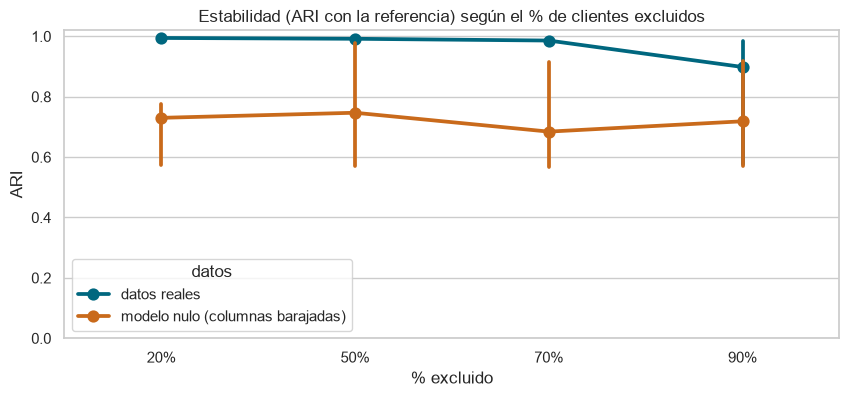

mean                                           min                                 
datos      datos reales modelo nulo (columnas barajadas) datos reales modelo nulo (columnas barajadas)
% excluido                                                                                            
20%               0.995                            0.730        0.993                            0.573
50%               0.992                            0.747        0.988                            0.571
70%               0.986                            0.684        0.983                            0.568
90%               0.898                            0.719        0.577                            0.571

In [13]:
rng = np.random.default_rng(7)
X_nulo = pd.DataFrame({c: rng.permutation(X[c].values) for c in X}, index=X.index)
ref_nulo = pd.Series(KMeans(K_FINAL, n_init=N_INIT_FINAL, random_state=SEMILLA).fit(X_nulo).labels_, index=X.index)

def jackknife_rapido(Xb, refb, frac, n=6):
    aris = []
    for i in range(n):
        dentro = np.random.default_rng(4000 + i).choice(ids, int(round(len(ids) * (1 - frac))), replace=False)
        lab = KMeans(K_FINAL, n_init=N_INIT_FINAL, random_state=4000 + i).fit(Xb.loc[dentro]).labels_
        aris.append(adjusted_rand_score(refb.loc[dentro], lab))
    return aris

estres = []
for frac in [0.2, 0.5, 0.7, 0.9]:
    for nombre, Xb, rb in [("datos reales", X, ref), ("modelo nulo (columnas barajadas)", X_nulo, ref_nulo)]:
        for a in jackknife_rapido(Xb, rb, frac):
            estres.append({"% excluido": f"{frac:.0%}", "datos": nombre, "ARI": a})
estres = pd.DataFrame(estres)
fig, ax = plt.subplots(figsize=(10, 4))
sns.pointplot(data=estres, x="% excluido", y="ARI", hue="datos", errorbar=("pi", 100), ax=ax, palette=["#00677F", "#c96a1b"])
ax.set(title="Estabilidad (ARI con la referencia) según el % de clientes excluidos", ylim=(0, 1.02))
plt.show()
estres.groupby(["datos", "% excluido"])["ARI"].agg(["mean", "min"]).unstack(0).round(3)

**Lectura:**
- Con los **datos reales**, la segmentación se mantiene casi intacta hasta excluir el **70 %** de los clientes (ARI
  ≥ 0,98 entrenando con ~52.000). Solo con el 10 % de los clientes (~17.000) alguna ejecución cae en la solución
  alternativa del apartado 8.
- Con los **datos barajados**, el ARI se queda en ~0,7 con cualquier tamaño, incluso con el 80 % de los datos: sin
  estructura, K-Means "corta" en sitios algo distintos cada vez. La estabilidad de nuestros segmentos **no es un artefacto** del algoritmo ni del tamaño de la muestra: hay
  estructura real en las combinaciones de variables (aunque los grupos se toquen, como dijo el silhouette).

## 8. La fragilidad escondida: dos soluciones casi empatadas

Todo lo anterior usa `n_init = 50`. Con el valor por defecto habitual (`n_init = 10`), el jackknife da otra imagen:

In [14]:
comp_ninit = []
for i in range(6):
    dentro = np.random.default_rng(5000 + i).choice(ids, int(round(len(ids) * .8)), replace=False)
    for n_init in [10, 50]:
        m = KMeans(K_FINAL, n_init=n_init, random_state=5000 + i).fit(X.loc[dentro])
        comp_ninit.append({"submuestra": i + 1, "n_init": n_init, "ARI con la referencia": adjusted_rand_score(ref.loc[dentro], m.labels_),
                           "inercia": m.inertia_, "etiquetas": pd.Series(m.labels_, index=dentro)})
comp_ninit = pd.DataFrame(comp_ninit)
comp_ninit.pivot(index="submuestra", columns="n_init", values=["ARI con la referencia", "inercia"]).round(3)

ARI con la referencia             inercia              
n_init                        10    50            10            50
submuestra                                                        
1                          0.992 0.993 1,074,195.733 1,074,193.879
2                          0.995 0.987 1,072,716.859 1,072,714.451
3                          0.616 0.993 1,074,226.867 1,072,326.309
4                          0.988 0.995 1,073,707.947 1,073,700.141
5                          0.611 0.996 1,074,348.271 1,073,008.569
6                          0.993 0.997 1,072,685.155 1,072,680.906

Con `n_init = 10`, **2 de cada 6** submuestras dan un ARI de ~0,61: una segmentación **distinta**. ¿Cuál?

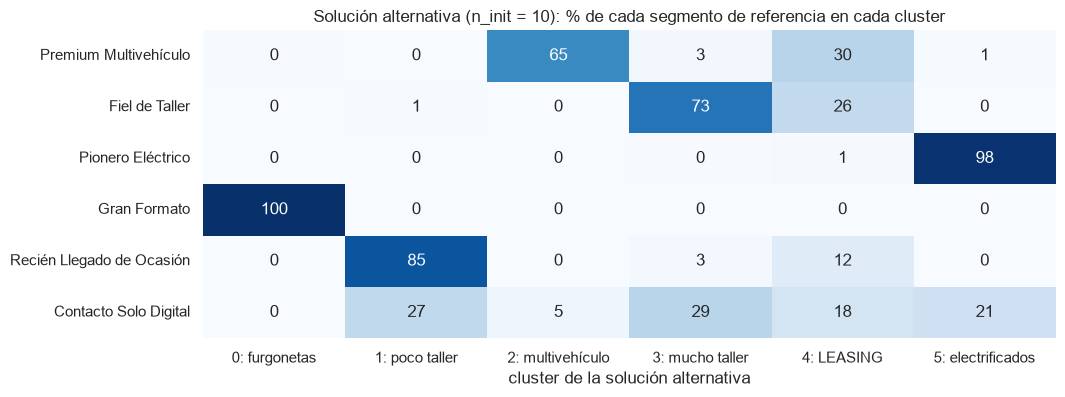

,inicializaciones (de 60) que acaban en esa inercia
"1,341,000",11
"1,343,000",22
"1,354,000",2
"1,360,000",6


In [15]:
peor = comp_ninit[comp_ninit["n_init"] == 10].sort_values("ARI con la referencia").iloc[0]
alt = peor["etiquetas"]
cm = pd.crosstab(seg_ref.loc[alt.index], alt, normalize="index").mul(100)
cen_alt = X.loc[alt.index].groupby(alt.values).mean()
etiqueta_alt = {c: ("LEASING" if cen_alt.loc[c, "finance_leasing_status"] > 1 else
                    "multivehículo" if cen_alt.loc[c, "n_vehiculos_historico"] > 1.5 else
                    "furgonetas" if cen_alt.loc[c, "pct_furgoneta"] > 2 else
                    "electrificados" if cen_alt.loc[c, "pct_electrificado"] > 1.5 else
                    "mucho taller" if cen_alt.loc[c, "visitas_taller_pct_pais"] > .5 else "poco taller") for c in cen_alt.index}
cm.columns = [f"{c}: {etiqueta_alt[c]}" for c in cm.columns]
fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(cm.reindex(ORDEN_SEGMENTOS), annot=True, fmt=".0f", cmap="Blues", ax=ax, cbar=False)
ax.set(title="Solución alternativa (n_init = 10): % de cada segmento de referencia en cada cluster", xlabel="cluster de la solución alternativa", ylabel="")
plt.show()
inercias = pd.Series([KMeans(K_FINAL, n_init=1, random_state=s).fit(X).inertia_ for s in range(60)])
optimos = inercias.round(-3).value_counts().sort_index().head(4)
optimos.index = [f"{v:,.0f}" for v in optimos.index]
optimos.rename("inicializaciones (de 60) que acaban en esa inercia").to_frame()

**Hallazgo:** existen **dos segmentaciones casi igual de buenas**:

| | Solución A (la de referencia) | Solución B (alternativa) |
|---|---|---|
| Inercia | la menor | solo ~0,15 % mayor |
| Segmento distintivo | **Contacto Solo Digital** (canal) | **Leasing activo** (relación financiera) |
| Qué pasa con el otro rasgo | El leasing se reparte entre Premium y el resto | Los clientes "solo email" se reparten entre los demás |
| Frecuencia con 1 inicialización | minoritaria | más frecuente |

Con una sola inicialización, K-Means llega el doble de veces a la B que a la A (22 frente a 11 de 60). Con 10
inicializaciones, entre 1 de cada 6 y 1 de cada 3 ejecuciones se queda en la B (2 de 6 en esta prueba). Con **50**, la probabilidad de no encontrar la A es prácticamente nula, y por eso el
jackknife principal es tan estable.

**Qué significa:**
- La segmentación es estable **porque buscamos bien el óptimo**, no porque sea la única posible. Si alguien del equipo
  re-entrena con `n_init = 10`, tiene una probabilidad apreciable de obtener otro reparto.
- **"Contacto Solo Digital" es el segmento estructuralmente más frágil**: en las ejecuciones bien optimizadas es muy
  estable (Jaccard ≥ 0,99), pero compite con una alternativa casi igual de buena en la que no existe. Es coherente con
  el Reto 4: es un segmento de **canal**, no de tipo de cliente.
- El **leasing** es una dimensión casi tan fuerte como el canal para segmentar. En la solución A aparece dentro de
  Premium Multivehículo (sub-perfil "Renovador en Leasing" del Reto 4).

## 9. ¿Era k = 6 una elección estable?

El jackknife también sirve para elegir k: un buen k da segmentaciones que se repiten al cambiar los datos. Para cada k
se hacen 8 submuestras (20 % excluido, `n_init = 50`) y se calcula el ARI medio entre pares de ejecuciones.

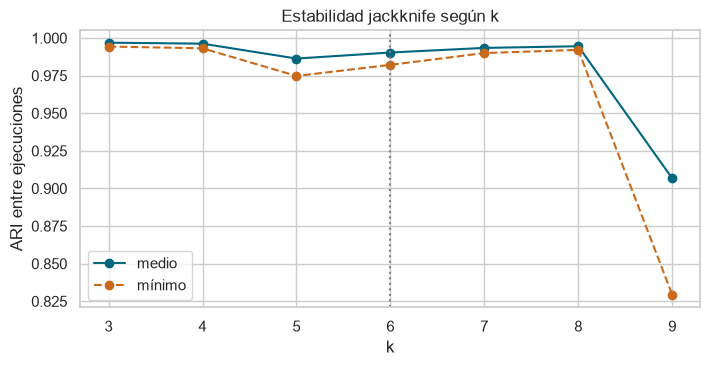

,ARI medio entre ejecuciones,ARI mínimo
3,0.997,0.994
4,0.996,0.993
5,0.986,0.975
6,0.990,0.982
7,0.993,0.990
8,0.995,0.992
9,0.907,0.829


In [16]:
estab_k = {}
for k in range(3, 10):
    labs = []
    for i in range(8):
        dentro = np.random.default_rng(3000 + i).choice(ids, int(round(len(ids) * .8)), replace=False)
        labs.append(pd.Series(KMeans(k, n_init=N_INIT_FINAL, random_state=3000 + i).fit(X.loc[dentro]).labels_, index=dentro))
    aris = [adjusted_rand_score(a.loc[a.index.intersection(b.index)], b.loc[a.index.intersection(b.index)]) for a, b in itertools.combinations(labs, 2)]
    estab_k[k] = {"ARI medio entre ejecuciones": np.mean(aris), "ARI mínimo": np.min(aris)}
estab_k = pd.DataFrame(estab_k).T
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(estab_k.index, estab_k["ARI medio entre ejecuciones"], marker="o", color="#00677F", label="medio")
ax.plot(estab_k.index, estab_k["ARI mínimo"], marker="o", ls="--", color="#c96a1b", label="mínimo")
ax.axvline(K_FINAL, ls=":", color="grey")
ax.set(title="Estabilidad jackknife según k", xlabel="k", ylabel="ARI entre ejecuciones")
ax.legend()
plt.show()
estab_k

Con `n_init = 50`, todos los k entre 3 y 8 dan segmentaciones muy estables (ARI ≥ 0,98); k = 5 es el más bajo de ese
rango y solo **k = 9** se desmarca (0,91). La estabilidad **no** discrimina entre k = 3 y 8: confirma que k = 6 no es una
elección frágil, y deja la decisión en el criterio de negocio del Reto 3.

## 10. Conclusiones y recomendación

**Clusters más y menos estables, y por qué:**

| Segmento | Estabilidad | Por qué |
|---|---|---|
| Gran Formato | Muy alta (≈ 0 % saltan) | Rasgo casi binario (furgoneta) |
| Pionero Eléctrico | Muy alta | Rasgo casi binario (electrificado) |
| Contacto Solo Digital | Alta, pero **frágil estructuralmente** | Compite con una solución alternativa casi igual de buena (segmento de leasing) |
| Recién Llegado de Ocasión | Alta | Frontera continua con Fiel de Taller (uso del taller) |
| Fiel de Taller | Alta, de las menos estables | Frontera con Recién Llegado y con Premium |
| Premium Multivehículo | Alta, la menos estable | Segmento heterogéneo (sub-perfiles del Reto 4) |

**Recomendación final:**
1. **La segmentación es robusta y se puede usar para decidir**: el 99,1 % de los clientes cae siempre en el mismo
   segmento al quitar un 20 % de los datos, todos los segmentos superan con holgura el umbral de estabilidad
   (Jaccard ≥ 0,99) y la estructura no aparece en datos sin relación entre variables.
2. **Mantener siempre `n_init = 50`** (ya fijado en `ajustar_kmeans` de `features.py`). Con 10 inicializaciones, una
   parte apreciable de los re-entrenamientos (2 de 6 en la prueba) da otro reparto. Al re-entrenar con datos nuevos, comprobar con el ARI que la
   segmentación no ha cambiado de solución.
3. **Marcar a los clientes de frontera** (el ~10 % con menor margen) como "segmento secundario" en el CRM: son los
   únicos que cambian, y lo hacen hacia su segundo segmento más cercano. A ellos les encajan mensajes de ambos.
4. **Tratar el canal como una capa aparte**: como "Contacto Solo Digital" compite con una segmentación por leasing,
   una opción robusta es usar el número de canales consentidos como **filtro de campaña** sobre todos los segmentos
   (en lugar de como segmento), y valorar el **leasing** como segmento en una próxima iteración.
5. **k = 6 es una elección estable** (ARI 0,99 entre ejecuciones). Con `n_init = 50`, todos los k entre 3 y 8 son
   estables y solo k = 9 baja (0,91). La estabilidad confirma que k = 6 no es una elección frágil, pero no decide entre
   k = 3 y 8: esa decisión sigue siendo la de negocio del Reto 3 (segmentar a toda la base en grupos accionables).